# Fase 4 - Modelado e iteraciones

Se entrenan **3 algoritmos en cada una de 2 iteraciones** y se comparan sobre el conjunto de **validación**. El test ciego se reserva para la Fase 5.

## 4.0 Preparación (reutiliza el flujo de la Fase 3)

In [1]:
from pathlib import Path
import warnings
warnings.filterwarnings("ignore")

ROOT = Path.cwd().resolve()
while not (ROOT / "Data" / "bank-full.csv").is_file() and ROOT.parent != ROOT:
    ROOT = ROOT.parent
DATA_PATH = ROOT / "Data" / "bank-full.csv"
MODELS_DIR = ROOT / "Modelos"

import matplotlib.pyplot as plt
import pandas as pd
from sklearn.model_selection import train_test_split

df = pd.read_csv(DATA_PATH, sep=";").drop_duplicates().reset_index(drop=True)
for col in df.select_dtypes(include=["object", "string"]).columns:
    df[col] = df[col].str.strip()
df["y"] = df["y"].map({"no": 0, "yes": 1}).astype("int8")

POST_CONTACT = ["duration", "campaign", "day", "month", "contact"]
X = df.drop(columns=["y"] + POST_CONTACT)
y = df["y"]

X_dev, X_test, y_dev, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=42)
X_train, X_val, y_train, y_val = train_test_split(X_dev, y_dev, test_size=0.25, stratify=y_dev, random_state=42)
print("Train:", X_train.shape, "| Validacion:", X_val.shape, "| Test ciego:", X_test.shape)

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

num_cols = X_train.select_dtypes(include="number").columns.tolist()
cat_cols = [c for c in X_train.columns if c not in num_cols]

def make_preprocessor():
    return ColumnTransformer([
        ("numeric", Pipeline([("imputer", SimpleImputer(strategy="median")),
                              ("scaler", StandardScaler())]), num_cols),
        ("categorical", Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                                  ("encoder", OneHotEncoder(handle_unknown="ignore"))]), cat_cols),
    ])

from sklearn.metrics import (accuracy_score, average_precision_score, f1_score,
                             precision_score, recall_score, roc_auc_score)

def evaluar(nombre, modelo, X_eval, y_eval):
    pred = modelo.predict(X_eval)
    proba = modelo.predict_proba(X_eval)[:, 1]
    return {"Modelo": nombre,
            "Accuracy": accuracy_score(y_eval, pred),
            "Precision": precision_score(y_eval, pred, zero_division=0),
            "Recall": recall_score(y_eval, pred, zero_division=0),
            "F1": f1_score(y_eval, pred, zero_division=0),
            "ROC-AUC": roc_auc_score(y_eval, proba),
            "PR-AUC": average_precision_score(y_eval, proba)}

resultados = []


Train: (27126, 11) | Validacion: (9042, 11) | Test ciego: (9043, 11)


## 4.1 Iteración 1 - Modelos base
Preprocesamiento estándar, sin balanceo de clases, sin selección avanzada ni ajuste de hiperparámetros (Random Forest acotado a 100 árboles, profundidad 12 y hoja mínima 5 para mantener un artefacto liviano).

### Iteración 1.1 - Regresión Logística

In [2]:
from sklearn.linear_model import LogisticRegression

it1_lr = Pipeline([("preprocessing", make_preprocessor()),
                   ("classifier", LogisticRegression(max_iter=1500, random_state=42))]).fit(X_train, y_train)
resultados.append(evaluar("Iteracion 1 | Regresion logistica", it1_lr, X_val, y_val))
pd.DataFrame(resultados).round(4)

,Modelo,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
0,Iteracion 1 | Regresion logistica,0.8943,0.6962,0.1711,0.2747,0.721,0.3585


### Iteración 1.2 - Árbol de Decisión

In [3]:
from sklearn.tree import DecisionTreeClassifier

it1_dt = Pipeline([("preprocessing", make_preprocessor()),
                   ("classifier", DecisionTreeClassifier(random_state=42))]).fit(X_train, y_train)
resultados.append(evaluar("Iteracion 1 | Arbol de decision", it1_dt, X_val, y_val))
pd.DataFrame(resultados).round(4)

,Modelo,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
0,Iteracion 1 | Regresion logistica,0.8943,0.6962,0.1711,0.2747,0.721,0.3585
1,Iteracion 1 | Arbol de decision,0.8194,0.2586,0.2911,0.2739,0.589,0.1584


### Iteración 1.3 - Random Forest

In [4]:
from sklearn.ensemble import RandomForestClassifier

it1_rf = Pipeline([("preprocessing", make_preprocessor()),
                   ("classifier", RandomForestClassifier(n_estimators=100, max_depth=12, min_samples_leaf=5,
                                                         random_state=42, n_jobs=1))]).fit(X_train, y_train)
resultados.append(evaluar("Iteracion 1 | Random Forest", it1_rf, X_val, y_val))
pd.DataFrame(resultados).round(4)

,Modelo,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
0,Iteracion 1 | Regresion logistica,0.8943,0.6962,0.1711,0.2747,0.7210,0.3585
1,Iteracion 1 | Arbol de decision,0.8194,0.2586,0.2911,0.2739,0.5890,0.1584
2,Iteracion 1 | Random Forest,0.8952,0.7148,0.1730,0.2785,0.7473,0.4059


### Conclusión Iteración 1
Los modelos base alcanzan Accuracy ≈ 0,82-0,90 pero **Recall bajo** en la clase `yes` (≈ 0,17 en regresión logística y Random Forest): predicen casi siempre `no`, que es la clase mayoritaria. El árbol sin restricciones sobreajusta (ROC-AUC ≈ 0,59). Esto motiva la Iteración 2.

## 4.2 Iteración 2 - Selección de características, balanceo y ajuste de hiperparámetros
Cada pipeline agrega `SelectPercentile(f_classif)`, **pesos de clase** para compensar el desbalance y `GridSearchCV` (3 folds, métrica F1) ejecutado solo con el conjunto de entrenamiento.

In [5]:
from sklearn.feature_selection import SelectPercentile, f_classif
from sklearn.model_selection import GridSearchCV, StratifiedKFold

cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

def buscar(clasificador, grilla):
    pipe = Pipeline([("preprocessing", make_preprocessor()),
                     ("selection", SelectPercentile(score_func=f_classif)),
                     ("classifier", clasificador)])
    gs = GridSearchCV(pipe, grilla, scoring="f1", cv=cv, n_jobs=1, refit=True)
    return gs.fit(X_train, y_train)

busquedas = {}

### Iteración 2.1 - Regresión Logística balanceada

In [6]:
gs = buscar(LogisticRegression(max_iter=1500, class_weight="balanced", random_state=42),
            {"selection__percentile": [50, 75], "classifier__C": [0.1, 1.0, 10.0]})
busquedas["Iteracion 2 | Regresion logistica"] = gs
print("Mejores hiperparametros:", gs.best_params_, "| F1 CV:", round(gs.best_score_, 4))
resultados.append(evaluar("Iteracion 2 | Regresion logistica", gs.best_estimator_, X_val, y_val))
pd.DataFrame(resultados).round(4).tail(1)

Mejores hiperparametros: {'classifier__C': 1.0, 'selection__percentile': 50} | F1 CV: 0.3206


,Modelo,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
3,Iteracion 2 | Regresion logistica,0.7042,0.2243,0.6219,0.3297,0.7233,0.354


### Iteración 2.2 - Árbol de Decisión balanceado

In [7]:
gs = buscar(DecisionTreeClassifier(class_weight="balanced", random_state=42),
            {"selection__percentile": [50, 75], "classifier__max_depth": [6, 12, None],
             "classifier__min_samples_leaf": [5, 20]})
busquedas["Iteracion 2 | Arbol de decision"] = gs
print("Mejores hiperparametros:", gs.best_params_, "| F1 CV:", round(gs.best_score_, 4))
resultados.append(evaluar("Iteracion 2 | Arbol de decision", gs.best_estimator_, X_val, y_val))
pd.DataFrame(resultados).round(4).tail(1)

Mejores hiperparametros: {'classifier__max_depth': 6, 'classifier__min_samples_leaf': 5, 'selection__percentile': 75} | F1 CV: 0.3541


,Modelo,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
4,Iteracion 2 | Arbol de decision,0.8562,0.3929,0.4197,0.4059,0.7211,0.3462


### Iteración 2.3 - Random Forest balanceado

In [8]:
gs = buscar(RandomForestClassifier(class_weight="balanced_subsample", random_state=42, n_jobs=1),
            {"selection__percentile": [50, 75], "classifier__n_estimators": [80, 120],
             "classifier__max_depth": [10, None], "classifier__min_samples_leaf": [2, 8]})
busquedas["Iteracion 2 | Random Forest"] = gs
print("Mejores hiperparametros:", gs.best_params_, "| F1 CV:", round(gs.best_score_, 4))
resultados.append(evaluar("Iteracion 2 | Random Forest", gs.best_estimator_, X_val, y_val))
pd.DataFrame(resultados).round(4).tail(1)

Mejores hiperparametros: {'classifier__max_depth': None, 'classifier__min_samples_leaf': 8, 'classifier__n_estimators': 80, 'selection__percentile': 75} | F1 CV: 0.3773


,Modelo,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
5,Iteracion 2 | Random Forest,0.8131,0.3205,0.5331,0.4003,0.7445,0.3986


## 4.3 Comparación en validación (Iteración 1 vs. Iteración 2)

,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
Modelo,,,,,,
Iteracion 1 | Regresion logistica,0.8943,0.6962,0.1711,0.2747,0.7210,0.3585
Iteracion 1 | Arbol de decision,0.8194,0.2586,0.2911,0.2739,0.5890,0.1584
Iteracion 1 | Random Forest,0.8952,0.7148,0.1730,0.2785,0.7473,0.4059
Iteracion 2 | Regresion logistica,0.7042,0.2243,0.6219,0.3297,0.7233,0.3540
Iteracion 2 | Arbol de decision,0.8562,0.3929,0.4197,0.4059,0.7211,0.3462
Iteracion 2 | Random Forest,0.8131,0.3205,0.5331,0.4003,0.7445,0.3986


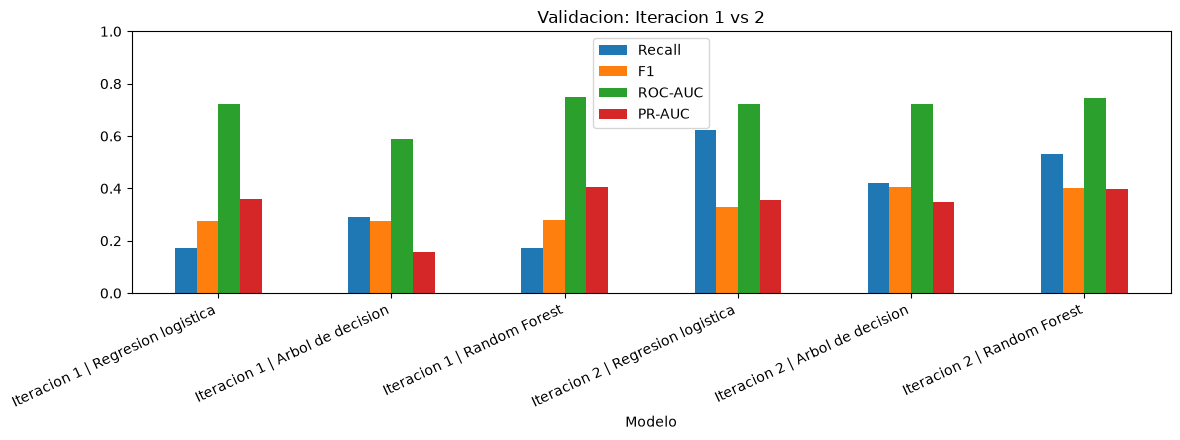

In [9]:
comparacion = pd.DataFrame(resultados).set_index("Modelo").round(4)
display(comparacion)
comparacion[["Recall", "F1", "ROC-AUC", "PR-AUC"]].plot(kind="bar", figsize=(12, 4.5), title="Validacion: Iteracion 1 vs 2")
plt.xticks(rotation=25, ha="right"); plt.ylim(0, 1); plt.tight_layout(); plt.show()

### Conclusión de la Fase 4
- La Iteración 2 **mejora fuertemente Recall y F1** respecto de la Iteración 1 gracias a los pesos de clase: por ejemplo, el Random Forest pasa de Recall ≈ 0,17 a ≈ 0,53 y el árbol de F1 ≈ 0,27 a ≈ 0,41.
- A cambio, la regresión logística y el Random Forest pierden Accuracy y Precision (se contacta a más clientes, con más falsos positivos). Es un compromiso esperado.
- El ROC-AUC se mantiene estable (≈ 0,72-0,75) salvo en el árbol, que mejora de ≈ 0,59 a ≈ 0,72 al regularizarse.
- Los seis pipelines finales se entrenan con `src/train_models.py` (misma configuración y semilla) y se guardan en `Modelos/` para la Fase 5 y la aplicación Streamlit.

## Checklist Fase 4
- [x] Iteración 1: 3 algoritmos base evaluados en validación
- [x] Iteración 2: selección de características, balanceo y GridSearchCV
- [x] Comparación de iteraciones
- [x] Modelos persistidos en `Modelos/`